# 💰 Personal Expense Tracker & Budget Dashboard: Analysis Notebook

**HCL Tech Data Analytics Project** · Domain: Banking & Finance

This notebook walks through the whole analysis **step by step**:

| Step | What we do |
|---|---|
| 1 | Set up libraries and project code |
| 2 | Load the raw bank-transaction data |
| 3 | Find the data-quality problems |
| 4 | Clean the data |
| 5 | Categorise expenses (needs vs wants, fixed vs variable) |
| 6 | Monthly analysis: income, expense, savings |
| 7 | Compare spending with the budget |
| 8 | Spending habits: payment modes, weekdays, 50/30/20 rule |
| 9 | Insights, recommendations and conclusion |

> **Note:** this notebook *reuses* the functions in the project's `src/` folder, so every number here matches the dashboard and the Excel report. It only **reads** files and never overwrites anything.

## 1. Setup

We import the libraries we need:
- **pandas**: works with tables of data (called *DataFrames*)
- **matplotlib**: draws charts

We also add the project's `src` folder to Python's search path, so we can import our own modules (`config`, `data_cleaning`, `analysis`).

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# The notebook lives in "notebooks/", so the project folder is one level up
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import config          # file paths and settings
import data_cleaning   # cleaning functions
import analysis        # all calculations (KPIs, budget, insights)

# Show numbers with 2 decimals and commas, and show more columns
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 25)

# Same colours as the rest of the project
BLUE, ORANGE, RED, AMBER, GREEN = "#2a78d6", "#eb6834", "#d03b3b", "#fab219", "#0ca30c"
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

def rupees(x, _pos=None):
    """Format chart axis numbers as ₹12k."""
    return f"₹{x / 1000:.0f}k" if abs(x) >= 1000 else f"₹{x:.0f}"

print("Setup complete. Project folder:", PROJECT_ROOT.name)

Setup complete. Project folder: personal expense tracker


## 2. Load the raw data

We have two input files:

1. **`transactions_raw.csv`**: 24 months (Jan 2024 to Dec 2025) of bank transactions for a salaried professional. It is *synthetic* (computer-generated), because real bank statements are private, but it follows realistic patterns.
2. **`monthly_budget.csv`**: the planned budget for each category in each month.

In [2]:
raw = pd.read_csv(config.RAW_TRANSACTIONS_FILE)
budget = pd.read_csv(config.BUDGET_FILE)

print("Raw transactions:", raw.shape[0], "rows ×", raw.shape[1], "columns")
print("Budget rows     :", budget.shape[0], "rows ×", budget.shape[1], "columns")
raw.head(10)

Raw transactions: 1303 rows × 8 columns
Budget rows     : 288 rows × 3 columns


,transaction_id,date,description,category,amount,txn_type,payment_mode,merchant
0,TXN000480,2024-09-23,Purchase at Office Canteen,Food & Dining,194.68,Debit,UPI,Office Canteen
1,TXN001023,2025-08-07,Purchase at PVR Cinemas,Entertainment,530.04,Debit,UPI,PVR Cinemas
2,TXN000299,19-Jun-2024,Purchase at Zomato,Food & Dining,645.3,Debit,UPI,Zomato
3,TXN001266,2025-12-19,Purchase at Delhi Metro Recharge,Transportation,475.6,Debit,UPI,Delhi Metro Recharge
4,TXN000775,2025-03-10,LIC Policy Premium Payment,Insurance,2200.0,Debit,Net Banking,LIC Policy Premium
5,TXN000116,2024-03-14,Purchase at Uber,Transportation,448.27,Debit,UPI,Uber
6,TXN000583,2024-11-19,Purchase at Uber,Transportation,524.18,Debit,UPI,Uber
7,TXN000528,21/10/2024,Purchase at Zomato,Food & Dining,756.01,Debit,Credit Card,Zomato
8,TXN000381,25/07/2024,Purchase at Myntra,NaN,1652.49,Debit,UPI,Myntra
9,TXN000102,2024-03-07,Netflix Payment,Subscriptions,₹649.00,Debit,Credit Card,Netflix


**What each column means**

| Column | Meaning |
|---|---|
| `transaction_id` | Unique ID of the transaction |
| `date` | When it happened |
| `description` | Text shown on the bank statement |
| `category` | Type of spending / income (Rent, Groceries, Salary, …) |
| `amount` | Amount in rupees (₹) |
| `txn_type` | **Debit** = money out, **Credit** = money in |
| `payment_mode` | UPI, Debit Card, Credit Card, Net Banking, Cash |
| `merchant` | Who was paid (Swiggy, DMart, …) |

In [3]:
# info() shows each column's data type and how many values are NOT missing
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   transaction_id  1303 non-null   str  
 1   date            1303 non-null   str  
 2   description     1303 non-null   str  
 3   category        1278 non-null   str  
 4   amount          1303 non-null   str  
 5   txn_type        1303 non-null   str  
 6   payment_mode    1264 non-null   str  
 7   merchant        1303 non-null   str  
dtypes: str(8)
memory usage: 184.1 KB


In [4]:
budget.head()

,month,category,budget_amount
0,2024-01,Rent,15000
1,2024-01,Groceries,8000
2,2024-01,Food & Dining,5500
3,2024-01,Transportation,6000
4,2024-01,Utilities,4500


## 3. Find the data-quality problems

Real data is never clean. Before analysing, we **inspect** the data for problems. Look closely at the `head()` output above: you can already spot dates in different formats, amounts like `₹526.37`, and labels like `DR`.

Let's count each problem.

In [5]:
# 1) Duplicate rows (the same transaction exported twice)
print("Duplicate rows            :", raw.duplicated().sum())

# 2) Missing values in each column
print("\nMissing values per column:")
print(raw.isna().sum())

Duplicate rows            : 25

Missing values per column:
transaction_id     0
date               0
description        0
category          25
amount             0
txn_type           0
payment_mode      39
merchant           0
dtype: int64


In [6]:
# 3) Dates that are NOT in the standard YYYY-MM-DD format
standard_date = raw["date"].str.match(r"^\d{4}-\d{2}-\d{2}$")
print("Non-standard dates:", (~standard_date).sum())
print("Examples:", raw.loc[~standard_date, "date"].head(5).tolist())

Non-standard dates: 195
Examples: ['19-Jun-2024', '21/10/2024', '25/07/2024', '13-Dec-2025', '05/02/2025']


In [7]:
# 4) Amounts stored as text with a ₹ symbol or commas
text_amounts = raw["amount"].astype(str).str.contains("₹|,", regex=True)
print("Amounts stored as text:", text_amounts.sum())
print("Examples:", raw.loc[text_amounts, "amount"].head(5).tolist())

# 5) Transaction type labels
print("\nTransaction type values:", raw["txn_type"].value_counts().to_dict())

Amounts stored as text: 103
Examples: ['₹649.00', '₹2,574.46', '₹9,500.00', '₹2,200.00', '₹134.72']

Transaction type values: {'Debit': 1197, 'Credit': 54, 'DR': 50, 'CR': 2}


In [8]:
# 6) The same category written in many different ways
print("Number of different category spellings:", raw["category"].nunique())
sorted(raw["category"].dropna().unique())

Number of different category spellings: 47


[' Entertainment ',
 ' Food & Dining ',
 ' Groceries ',
 ' Healthcare ',
 ' Insurance ',
 ' Shopping ',
 ' Transportation ',
 ' Utilities ',
 'EDUCATION',
 'ENTERTAINMENT',
 'Education',
 'Entertainment',
 'FOOD & DINING',
 'FREELANCE',
 'Food & Dining',
 'Food and Dining',
 'Freelance',
 'GROCERIES',
 'Groceries',
 'HEALTHCARE',
 'Healthcare',
 'INSURANCE',
 'Insurance',
 'Interest',
 'Refund',
 'Rent',
 'SALARY',
 'SHOPPING',
 'SUBSCRIPTIONS',
 'Salary',
 'Shopping',
 'Subscriptions',
 'TRANSPORTATION',
 'Transportation',
 'Travel',
 'UTILITIES',
 'Utilities',
 'entertainment',
 'food & dining',
 'freelance',
 'groceries',
 'rent',
 'salary',
 'shopping',
 'subscriptions',
 'transportation',
 'utilities']

**Summary of problems found:** duplicates, missing categories and payment modes, three different date formats, amounts stored as text, `DR`/`CR` instead of `Debit`/`Credit`, and categories written in upper case, lower case, with extra spaces, or with "and" instead of "&". There are only **16 real categories**, but the column contains many more spellings.

*(These counts include the duplicate rows. The cleaning log in the next step removes duplicates first, so a few of its numbers are slightly smaller.)*

## 4. Clean the data

The cleaning logic lives in `src/data_cleaning.py`. Before running all of it, let's try the small helper functions on single values to see how they work.

In [9]:
# parse_date() tries each known format until one works.
# It reads 05/01/2024 as 5 January (Indian day-first style), NOT 1 May.
for text in ["2024-01-05", "05/01/2024", "05-Jan-2024"]:
    print(f"{text:<12} ->", data_cleaning.parse_date(text).date())

2024-01-05   -> 2024-01-05
05/01/2024   -> 2024-01-05
05-Jan-2024  -> 2024-01-05


In [10]:
# parse_amount() removes the ₹ symbol and commas, then converts text to a number
for value in ["₹1,250.50", "300", 99.9]:
    print(f"{str(value):<10} ->", data_cleaning.parse_amount(value))

₹1,250.50  -> 1250.5
300        -> 300.0
99.9       -> 99.9


In [11]:
# standardise_category() maps every spelling to the official name
for text in ["GROCERIES", " Rent ", "food and dining", "FOOD & DINING"]:
    print(f"{text!r:<18} ->", data_cleaning.standardise_category(text))

'GROCERIES'        -> Groceries
' Rent '           -> Rent
'food and dining'  -> Food & Dining
'FOOD & DINING'    -> Food & Dining


Now we run the **complete 9-step cleaning pipeline**. It prints a log of what each step fixed:

1. Remove duplicates
2. Standardise dates
3. Convert text amounts to numbers and fix negative signs
4. `DR`/`CR` → `Debit`/`Credit`
5. Standardise category names
6. Fill missing categories using the merchant (e.g. "Swiggy" is always *Food & Dining*)
7. Fill missing payment modes with "Unknown"
8. Remove typing errors (an amount more than 20× the merchant's usual amount)
9. Add new helpful columns (month, weekday, expense type, …)

In [12]:
df, log = data_cleaning.clean_transactions(raw)

  - Loaded raw data: 1,303 rows, 8 columns
  - Removed 25 duplicate rows
  - Standardised 191 dates written in non-ISO formats; dropped 0 unparseable dates
  - Converted 102 text amounts to numbers; fixed 11 negative amounts; dropped 0 rows with no amount
  - Standardised 51 transaction-type labels (DR/CR -> Debit/Credit)
  - Standardised 102 inconsistent category spellings
  - Filled 25 of 25 missing categories using merchant name (0 left as 'Uncategorised')
  - Filled 38 missing payment modes with 'Unknown' (not guessed, to stay honest)
  - Removed 3 data-entry errors (amount > 20x merchant median): Swiggy ₹31,950, Starbucks ₹60,631, Domino's ₹70,597
  - Flagged 69 genuine large spends using the IQR rule (kept in data)
  - Added features: year, month, month_name, year_month, quarter, day_of_week, is_weekend, signed_amount, expense_type, cost_nature, is_large_spend
  - Final clean data: 1,275 rows, 19 columns, 0 missing values remaining


In [13]:
print("Before cleaning:", raw.shape, "  After cleaning:", df.shape)
print("Missing values left:", df.isna().sum().sum())
print("Duplicate IDs left :", df["transaction_id"].duplicated().sum())
print("Categories now     :", df["category"].nunique())
df.head()

Before cleaning: (1303, 8)   After cleaning: (1275, 19)
Missing values left: 0
Duplicate IDs left : 0
Categories now     : 16


,transaction_id,date,description,category,amount,txn_type,payment_mode,merchant,is_large_spend,year,month,month_name,year_month,quarter,day_of_week,is_weekend,signed_amount,expense_type,cost_nature
0,TXN000001,2024-01-01,Salary Credit - TechNova Pvt Ltd,Salary,"68,000.00",Credit,Net Banking,TechNova Pvt Ltd,False,2024,1,Jan,2024-01,Q1,Monday,False,"68,000.00",Income,Income
1,TXN000002,2024-01-01,Purchase at DMart,Groceries,"1,812.85",Debit,UPI,DMart,False,2024,1,Jan,2024-01,Q1,Monday,False,"-1,812.85",Essential,Variable
2,TXN000003,2024-01-02,Purchase at Amazon,Shopping,918.43,Debit,UPI,Amazon,False,2024,1,Jan,2024-01,Q1,Tuesday,False,-918.43,Discretionary,Variable
3,TXN000004,2024-01-02,Purchase at Rapido,Transportation,77.03,Debit,UPI,Rapido,False,2024,1,Jan,2024-01,Q1,Tuesday,False,-77.03,Essential,Variable
4,TXN000005,2024-01-03,Purchase at Myntra,Shopping,"1,302.33",Debit,Unknown,Myntra,False,2024,1,Jan,2024-01,Q1,Wednesday,False,"-1,302.33",Discretionary,Variable


**Consistency check:** the project's pipeline (`python main.py`) saved its cleaned data to `data/processed/transactions_clean.csv`. Our notebook result should be **exactly the same**.

In [14]:
saved = pd.read_csv(config.CLEAN_TRANSACTIONS_FILE, parse_dates=["date"])
same = (len(saved) == len(df)
        and (saved["transaction_id"].values == df["transaction_id"].values).all()
        and (saved["amount"].round(2).values == df["amount"].round(2).values).all())
print("Notebook cleaning matches the saved clean file:", same)

Notebook cleaning matches the saved clean file: True


## 5. Expense categorisation

Each transaction belongs to one of **12 expense categories** or **4 income categories**. During cleaning we also grouped expenses in two useful ways:

| Grouping | Values | Meaning |
|---|---|---|
| `expense_type` | **Essential** | Needs: rent, groceries, utilities, healthcare, insurance, transport, education |
| | **Discretionary** | Wants: shopping, food & dining, entertainment, travel, subscriptions |
| `cost_nature` | **Fixed** | The same every month (rent, insurance, subscriptions, utility bills) |
| | **Variable** | Changes with behaviour (groceries, shopping, …) |

In [15]:
expenses = analysis.expenses_only(df)   # only money going OUT

# Which group does each category belong to?
expenses.groupby(["expense_type", "cost_nature"])["category"].unique().to_frame("categories")

categories
expense_type  cost_nature                                                   
Discretionary Fixed                                          [Subscriptions]
              Variable      [Shopping, Food & Dining, Entertainment, Travel]
Essential     Fixed                             [Rent, Utilities, Insurance]
              Variable     [Groceries, Transportation, Healthcare, Educat...

In [16]:
cats = analysis.category_summary(df)
cats

,category,total_spent,num_transactions,avg_transaction,avg_per_month,share_pct
0,Rent,"369,000.00",24,"15,375.00","15,375.00",25.26
1,Shopping,"191,944.01",85,"2,258.16","7,997.67",13.14
2,Groceries,"162,982.70",184,885.78,"6,790.95",11.16
3,Food & Dining,"147,922.21",277,534.02,"6,163.43",10.13
4,Transportation,"134,603.48",297,453.21,"5,608.48",9.21
5,Insurance,"89,800.00",26,"3,453.85","3,741.67",6.15
6,Utilities,"86,056.09",96,896.42,"3,585.67",5.89
7,Travel,"75,855.16",16,"4,740.95","3,160.63",5.19
8,Entertainment,"64,362.46",61,"1,055.12","2,681.77",4.41
9,Healthcare,"61,019.81",41,"1,488.29","2,542.49",4.18


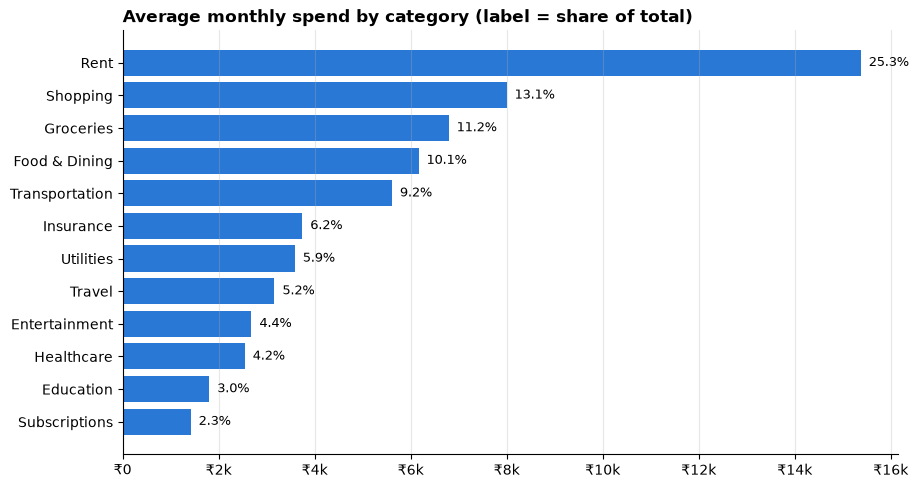

In [17]:
data = cats.sort_values("total_spent")
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(data["category"], data["avg_per_month"], color=BLUE)
ax.bar_label(bars, labels=[f"  {s:.1f}%" for s in data["share_pct"]], fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(rupees))
ax.set_title("Average monthly spend by category (label = share of total)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.show()

In [18]:
# Needs vs wants, as a share of all spending
split = expenses.groupby("expense_type")["amount"].sum()
(split / split.sum() * 100).round(1).to_frame("share of spending (%)")

,share of spending (%)
expense_type,
Discretionary,35.20
Essential,64.80


**What we learn:** Rent alone is about a quarter of all spending. Rent, Shopping and Groceries together make up roughly **half**. Shopping is the biggest *discretionary* category, so it is where the most money can be saved.

## 6. Monthly analysis

Now we look at each month: how much came in, how much went out, and how much was saved.

- **savings** = income − expense
- **savings rate** = savings ÷ income × 100
- **cumulative savings** = running total of savings

In [19]:
k = analysis.kpi_summary(df)
for name, value in k.items():
    print(f"{name:<25}: {value:,}" if isinstance(value, (int, float)) else f"{name:<25}: {value}")

total_income             : 1,883,674.03
total_expense            : 1,460,802.19
net_savings              : 422,871.84
savings_rate_pct         : 22.4
months_covered           : 24
avg_monthly_income       : 78,486.42
avg_monthly_expense      : 60,866.76
num_transactions         : 1,275
num_expense_txns         : 1,221
avg_transaction_value    : 1,196.4
top_spending_category    : Rent


In [20]:
monthly = analysis.monthly_summary(df)
monthly

txn_type,year_month,income,expense,savings,savings_rate_pct,expense_mom_change_pct,cumulative_savings
0,2024-01,"68,000.00","51,866.04","16,133.96",23.70,NaN,"16,133.96"
1,2024-02,"87,594.28","41,825.07","45,769.21",52.30,-19.40,"61,903.17"
2,2024-03,"74,266.27","73,633.82",632.45,0.90,76.10,"62,535.62"
3,2024-04,"68,000.00","59,043.61","8,956.39",13.20,-19.80,"71,492.01"
4,2024-05,"75,500.00","72,726.66","2,773.34",3.70,23.20,"74,265.35"
5,2024-06,"80,887.69","68,889.79","11,997.90",14.80,-5.30,"86,263.25"
6,2024-07,"68,991.94","73,163.35","-4,171.41",-6.00,6.20,"82,091.84"
7,2024-08,"78,300.00","56,660.86","21,639.14",27.60,-22.60,"103,730.98"
8,2024-09,"84,134.69","40,919.14","43,215.55",51.40,-27.80,"146,946.53"
9,2024-10,"81,264.06","54,150.23","27,113.83",33.40,32.30,"174,060.36"


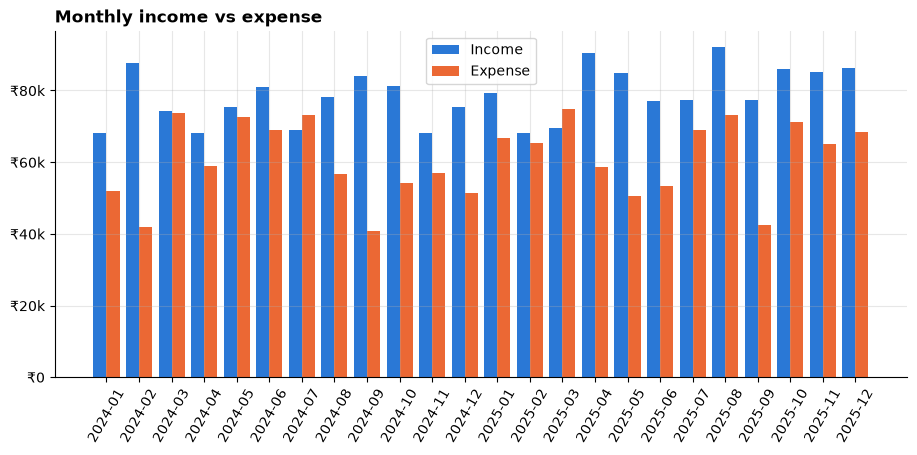

In [21]:
x = range(len(monthly))
fig, ax = plt.subplots()
ax.bar([i - 0.2 for i in x], monthly["income"], width=0.4, color=BLUE, label="Income")
ax.bar([i + 0.2 for i in x], monthly["expense"], width=0.4, color=ORANGE, label="Expense")
ax.set_xticks(list(x), monthly["year_month"], rotation=60)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rupees))
ax.set_title("Monthly income vs expense", loc="left", fontweight="bold")
ax.legend()
plt.show()

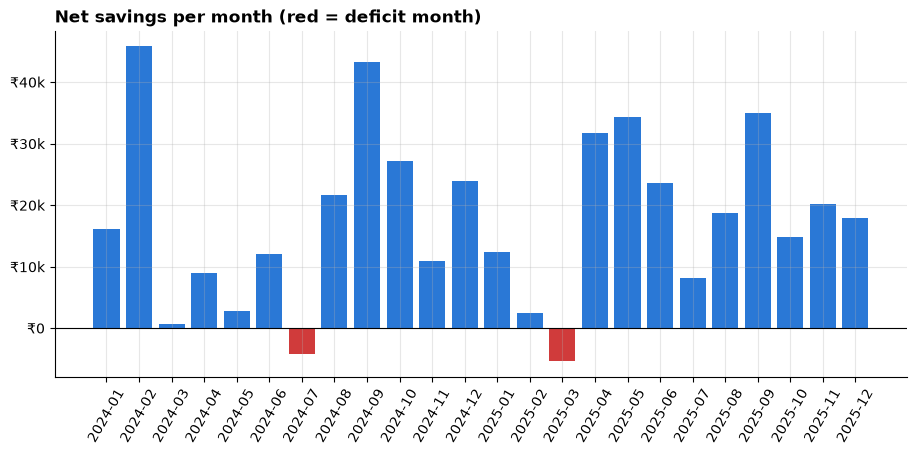

In [22]:
# Blue bar = money saved, red bar = deficit (spent more than earned)
colors = [BLUE if s >= 0 else RED for s in monthly["savings"]]
fig, ax = plt.subplots()
ax.bar(monthly["year_month"], monthly["savings"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.tick_params(axis="x", rotation=60)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rupees))
ax.set_title("Net savings per month (red = deficit month)", loc="left", fontweight="bold")
plt.show()

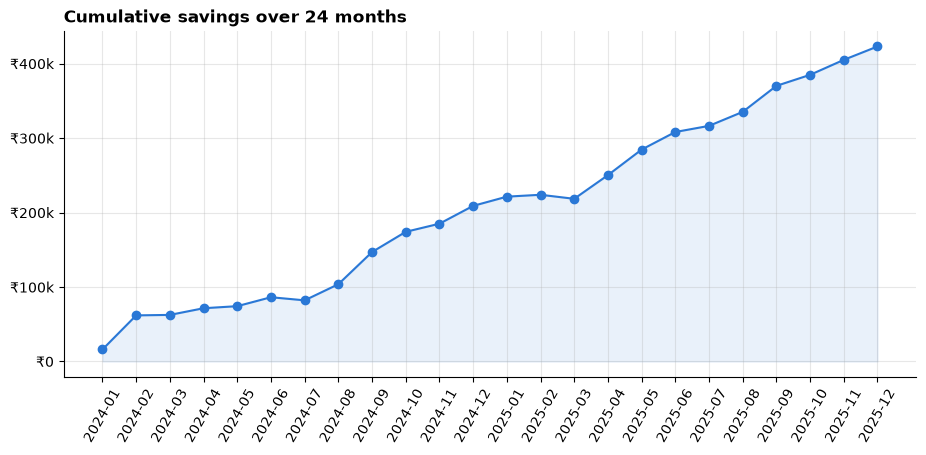

In [23]:
fig, ax = plt.subplots()
ax.plot(monthly["year_month"], monthly["cumulative_savings"], color=BLUE, marker="o")
ax.fill_between(monthly["year_month"], monthly["cumulative_savings"], color=BLUE, alpha=0.1)
ax.tick_params(axis="x", rotation=60)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rupees))
ax.set_title("Cumulative savings over 24 months", loc="left", fontweight="bold")
plt.show()

In [24]:
best = monthly.loc[monthly["savings"].idxmax()]
worst = monthly.loc[monthly["savings"].idxmin()]
print(f"Best month : {best['year_month']}  saved {analysis.fmt_money(best['savings'])}")
print(f"Worst month: {worst['year_month']}  net   {analysis.fmt_money(worst['savings'])}")  # shows -₹5,414
print("Deficit months:", monthly.loc[monthly["savings"] < 0, "year_month"].tolist())

Best month : 2024-02  saved ₹45,769
Worst month: 2025-03  net   -₹5,414
Deficit months: ['2024-07', '2025-03']


**What we learn:** the person saves money in almost every month. The deficit months match real-life events: **March** (yearly health-insurance premium) and months with travel or course fees. Cumulative savings rise steadily over the two years.

## 7. Budget comparison

The budget file has a planned amount for every category in every month. For each one we calculate:

- **utilisation %** = actual spent ÷ budget × 100
- **variance** = budget − actual (positive = money saved, negative = overspent)
- **status**: 🟢 *Within Budget* (< 80%) · 🟡 *Near Limit* (80–100%) · 🔴 *Over Budget* (> 100%)

In [25]:
bva = analysis.budget_vs_actual(df, budget)
print(bva.shape[0], "rows = 12 categories × 24 months")
bva.head(12)

288 rows = 12 categories × 24 months


,month,category,budget_amount,actual_spent,variance,utilisation_pct,status
0,2024-01,Rent,15000,"15,000.00",0.00,100.00,Near Limit
1,2024-01,Groceries,8000,"4,582.24","3,417.76",57.30,Within Budget
2,2024-01,Food & Dining,5500,"2,448.90","3,051.10",44.50,Within Budget
3,2024-01,Transportation,6000,"6,326.91",-326.91,105.40,Over Budget
4,2024-01,Utilities,4500,"2,738.00","1,762.00",60.80,Within Budget
5,2024-01,Shopping,6000,"7,950.71","-1,950.71",132.50,Over Budget
6,2024-01,Entertainment,2500,"2,003.62",496.38,80.10,Near Limit
7,2024-01,Healthcare,2500,857.18,"1,642.82",34.30,Within Budget
8,2024-01,Education,1500,"6,342.48","-4,842.48",422.80,Over Budget
9,2024-01,Travel,4000,0.00,"4,000.00",0.00,Within Budget


In [26]:
# Roll up to one row per category for the whole 24 months
overview = analysis.budget_category_overview(bva)
overview

,category,total_budget,total_actual,months_over_budget,months_tracked,variance,utilisation_pct,status
0,Shopping,156000,"191,944.01",16,24,"-35,944.01",123.00,Over Budget
1,Education,36000,"43,272.27",10,24,"-7,272.27",120.20,Over Budget
2,Entertainment,60000,"64,362.46",13,24,"-4,362.46",107.30,Over Budget
3,Food & Dining,138000,"147,922.21",12,24,"-9,922.21",107.20,Over Budget
4,Healthcare,60000,"61,019.81",10,24,"-1,019.81",101.70,Over Budget
5,Insurance,89800,"89,800.00",0,24,0.00,100.00,Near Limit
6,Rent,369000,"369,000.00",0,24,0.00,100.00,Near Limit
7,Subscriptions,36000,"33,984.00",0,24,"2,016.00",94.40,Near Limit
8,Transportation,144000,"134,603.48",11,24,"9,396.52",93.50,Near Limit
9,Groceries,198000,"162,982.70",8,24,"35,017.30",82.30,Near Limit


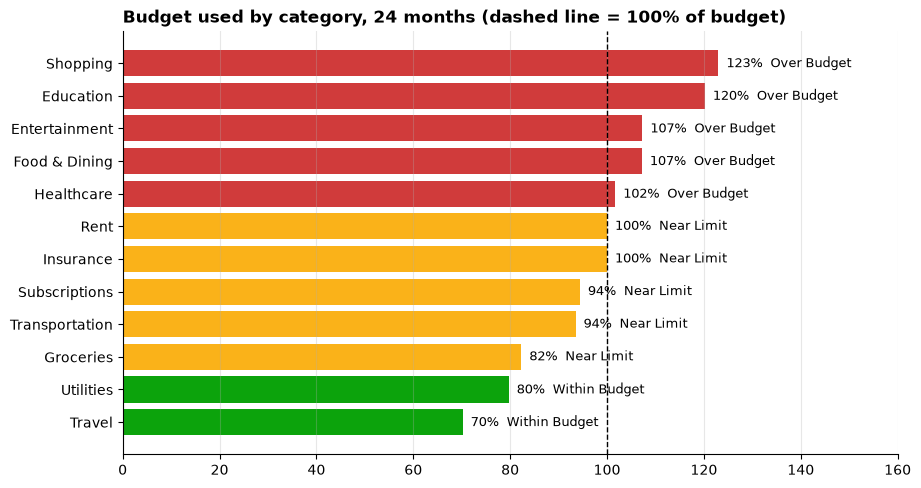

In [27]:
data = overview.sort_values("utilisation_pct")
status_colors = {"Within Budget": GREEN, "Near Limit": AMBER, "Over Budget": RED}
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(data["category"], data["utilisation_pct"],
               color=[status_colors[s] for s in data["status"]])
ax.bar_label(bars, labels=[f"  {p:.0f}%  {s}" for p, s in zip(data["utilisation_pct"], data["status"])], fontsize=9)
ax.axvline(100, color="black", linestyle="--", linewidth=1)
ax.set_xlim(0, 160)
ax.set_title("Budget used by category, 24 months (dashed line = 100% of budget)", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.show()

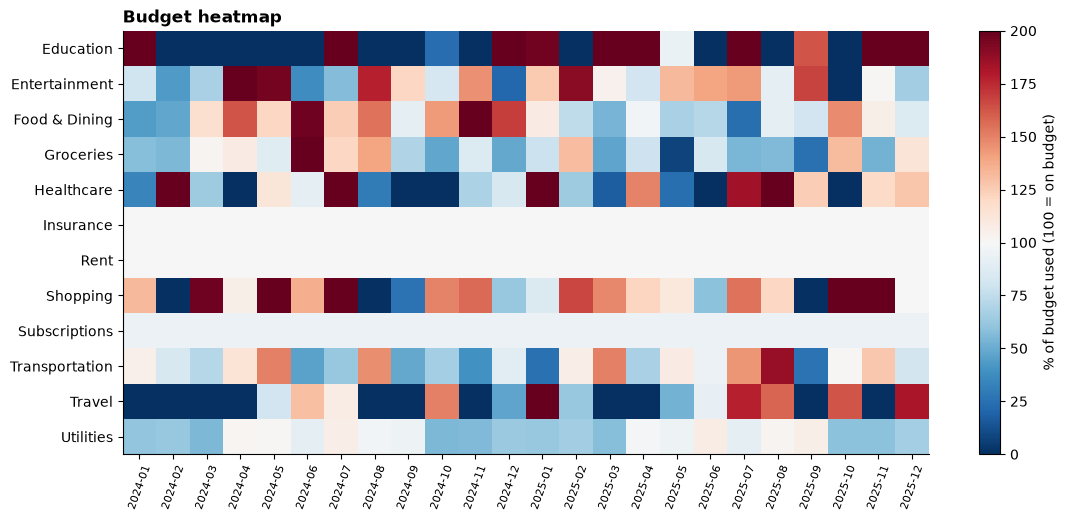

In [28]:
# Heatmap: every category in every month. Red = overspent, blue = under budget.
matrix = bva.pivot(index="category", columns="month", values="utilisation_pct").clip(upper=200)
fig, ax = plt.subplots(figsize=(13, 5.5))
image = ax.imshow(matrix, aspect="auto", cmap="RdBu_r", vmin=0, vmax=200)
ax.set_yticks(range(len(matrix)), matrix.index)
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=70, fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, label="% of budget used (100 = on budget)")
ax.set_title("Budget heatmap", loc="left", fontweight="bold")
plt.show()

### Budget alerts for one month

The dashboard shows alerts for any chosen month. Here we do the same for **October 2025** (festive season). Fixed bills paid exactly as planned (like rent) are skipped, because they are expected.

In [29]:
alerts = analysis.budget_alerts(bva, "2025-10")
for row in alerts.itertuples():
    icon = "🔴" if row.status == "Over Budget" else "🟡"
    print(f"{icon} {row.category:<15} spent ₹{row.actual_spent:>9,.0f} of ₹{row.budget_amount:>7,.0f}  ({row.utilisation_pct:.0f}%)")

🔴 Shopping        spent ₹   14,987 of ₹  7,000  (214%)
🔴 Travel          spent ₹    8,148 of ₹  5,000  (163%)
🔴 Food & Dining   spent ₹    8,843 of ₹  6,000  (147%)
🔴 Groceries       spent ₹   11,223 of ₹  8,500  (132%)
🔴 Transportation  spent ₹    6,050 of ₹  6,000  (101%)
🟡 Subscriptions   spent ₹    1,416 of ₹  1,500  (94%)


**What we learn:** **Shopping** is the biggest problem. It went over budget in **16 of 24 months**. Education, Entertainment and Food & Dining are also over budget overall, while Utilities and Travel stay safely within their budgets.

## 8. Spending habits

### 8.1 How does the person pay?

In [30]:
pay = analysis.payment_mode_summary(df)
pay

,payment_mode,total_spent,num_transactions,share_pct
0,UPI,"602,763.80",672,41.26
1,Net Banking,"441,855.58",79,30.25
2,Credit Card,"221,081.12",228,15.13
3,Debit Card,"116,148.26",124,7.95
4,Cash,"54,132.01",83,3.71
5,Unknown,"24,821.42",35,1.70


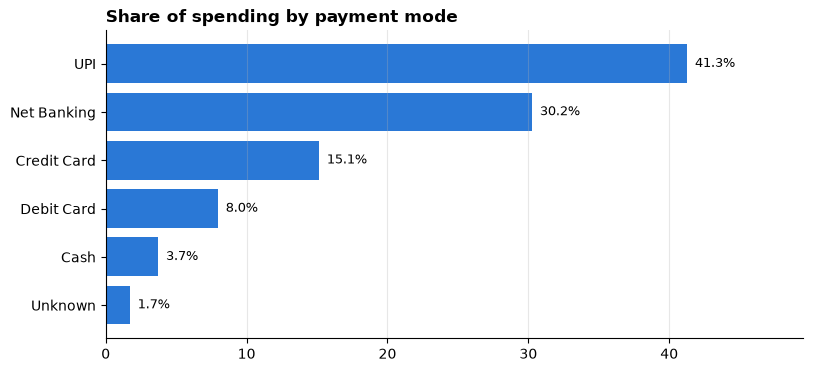

In [31]:
data = pay.sort_values("share_pct")
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(data["payment_mode"], data["share_pct"], color=BLUE)
ax.bar_label(bars, labels=[f"  {v:.1f}%" for v in data["share_pct"]], fontsize=9)
ax.set_xlim(0, data["share_pct"].max() * 1.2)
ax.set_title("Share of spending by payment mode", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
plt.show()

### 8.2 Which day of the week has the most spending?

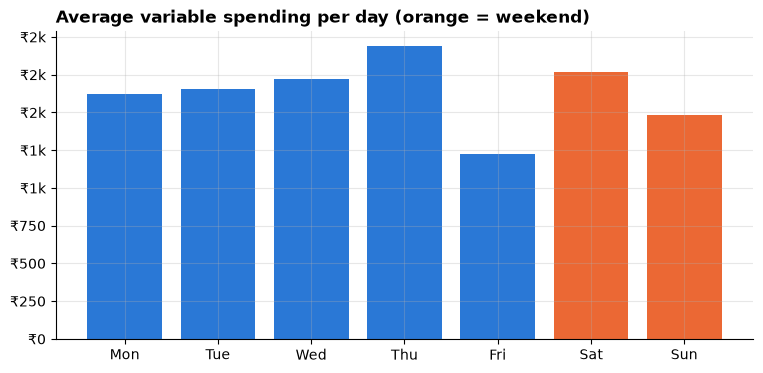

In [32]:
weekday = analysis.weekday_summary(df)   # fixed bills excluded, as their date is not a choice
colors = [ORANGE if d in ("Saturday", "Sunday") else BLUE for d in weekday["day_of_week"]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weekday["day_of_week"].str[:3], weekday["avg_daily_spend"], color=colors)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rupees))
ax.set_title("Average variable spending per day (orange = weekend)", loc="left", fontweight="bold")
plt.show()

### 8.3 The 50/30/20 rule

A popular personal-finance guideline: spend **50%** of income on needs, **30%** on wants, and save **20%**.

In [33]:
nws = analysis.needs_wants_savings(df)
nws

,bucket,amount,actual_pct,recommended_pct
0,Needs,"946,734.40",50.30,50
1,Wants,"514,067.80",27.30,30
2,Savings,"422,871.80",22.40,20


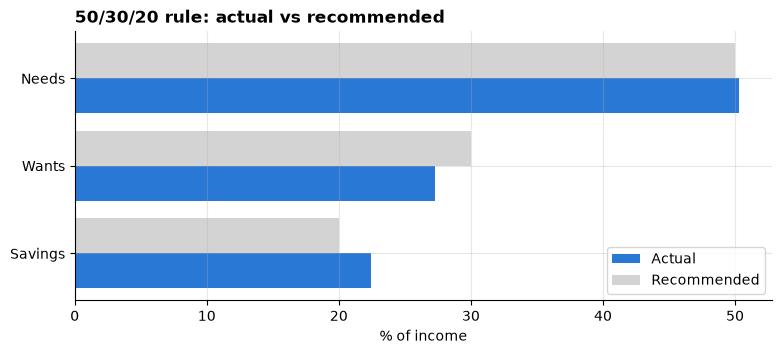

In [34]:
y = range(len(nws))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh([i + 0.2 for i in y], nws["actual_pct"], height=0.4, color=BLUE, label="Actual")
ax.barh([i - 0.2 for i in y], nws["recommended_pct"], height=0.4, color="lightgrey", label="Recommended")
ax.set_yticks(list(y), nws["bucket"])
ax.invert_yaxis()
ax.set_xlabel("% of income")
ax.set_title("50/30/20 rule: actual vs recommended", loc="left", fontweight="bold")
ax.legend()
plt.show()

**What we learn:** almost all spending is digital, with UPI the most used method. The person follows the 50/30/20 rule well: needs are about 50%, wants are below 30%, and savings are **above 20%**.

## 9. Insights, recommendations and conclusion

`analysis.generate_insights()` turns the numbers into plain-English sentences. The same text appears in the dashboard and the Excel report.

In [35]:
insights, recommendations = analysis.generate_insights(df, budget)

print("KEY INSIGHTS")
for i, line in enumerate(insights, 1):
    print(f"{i:>2}. {line}")

print("\nRECOMMENDATIONS")
for i, line in enumerate(recommendations, 1):
    print(f"{i:>2}. {line}")

KEY INSIGHTS
 1. Over 24 months the user earned ₹1,883,674 and spent ₹1,460,802, saving ₹422,872 (savings rate 22.4%).
 2. Top 3 spending categories: Rent (25.3%), Shopping (13.1%), Groceries (11.2%) - together 49.6% of all spending.
 3. Best month: 2024-02 (saved ₹45,769). Worst month: 2025-03 (net -₹5,414).
 4. Spending exceeded income in 2 month(s): 2024-07, 2025-03.
 5. Shopping went over budget in 16 of 24 months (overall 123.0% of budget used).
 6. Education went over budget in 10 of 24 months (overall 120.2% of budget used).
 7. Entertainment went over budget in 13 of 24 months (overall 107.3% of budget used).
 8. 50/30/20 check: savings are 22.4% of income, which meets the 20% target; wants take 27.3% (target 30%).
 9. 94.6% of spending is digital; UPI alone is 41.3%.
10. Festive effect: Shopping in Oct-Nov is 1.6x a normal month - plan a dedicated Diwali fund.

RECOMMENDATIONS
 1. Review the Shopping budget: when it is exceeded, overspend averages ₹4,097.
 2. Review the Educat

### Conclusion

In this notebook we:

1. **Loaded** 24 months of raw bank transactions and a monthly budget.
2. **Found and fixed** real-world data problems: duplicates, three date formats, text amounts, inconsistent categories, missing values and typing errors.
3. **Categorised** spending into needs/wants and fixed/variable.
4. **Analysed** monthly cash flow: the person saves about **22%** of their income.
5. **Compared** spending with the budget: **Shopping** is the main overspending category.
6. **Studied habits**: mostly digital (UPI) payments, and the 50/30/20 rule is met.

**Next steps:** run `streamlit run dashboard/app.py` to explore the same analysis interactively, with filters, budget alerts and a what-if savings simulator.